# Laboratorio di Analisi Numerica
## Lezione 11

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
14 dicembre 2023

*Conversione della dispensa «Laboratorio 11.tex»; data mantenuta dall’originale.*

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione usa `LinearAlgebra`, `FFTW` e `Plots`. Per la sezione sulle immagini servono anche `FileIO`, `ImageIO` e `Colors`. Installate i pacchetti mancanti una sola volta con `using Pkg; Pkg.add(["FFTW", "Plots", "FileIO", "ImageIO", "Colors"])`.

Eseguite le celle dall’alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite. Ogni notebook è indipendente dagli altri.

In [ ]:
using LinearAlgebra
using FFTW
using Plots

## 1. Approssimazione funzionale con la DFT

Consideriamo lo spazio $V_n$ generato da $\mathcal F_n=\{1,z,\ldots,z^{n-1}\}$, come funzioni da $\mathbb S^1=\{z\in\mathbb C:|z|=1\}$ a $\mathbb C$. Su questo spazio definiamo

$$\langle f,g\rangle=\frac1n\sum_{j=0}^{n-1}\overline{f(e^{2\pi i j/n})}\,g(e^{2\pi i j/n}).$$

Verificate che su $V_n$ è effettivamente un prodotto scalare. Su uno spazio più grande di funzioni, la stessa formula può essere solo semidefinita: funzioni non nulle possono annullarsi in tutti i nodi.

### Esercizio 1 (facoltativo)

Verificate che $\mathcal F_n$ è ortonormale: $\langle z^i,z^j\rangle$ vale $1$ se $i=j$ e $0$ altrimenti, per $0\leq i,j<n$.

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 1.*

Una funzione $2\pi$-periodica $s(\theta)$ corrisponde a una funzione sulla circonferenza ponendo $f_s(e^{i\theta})=s(\theta)$. Sotto opportune ipotesi di regolarità possiamo scrivere una serie di Laurent

$$f(z)=\sum_{j\in\mathbb Z}c_jz^j.$$

Se i coefficienti decadono rapidamente, approssimiamo con un numero finito di termini:

$$f(z)=\sum_{j=-k}^k c_jz^j+r_k(z).$$

Moltiplicando per $z^k$ otteniamo un polinomio di grado $2k$ più il resto:

$$z^kf(z)=\sum_{j=0}^{2k}c_{j-k}z^j+z^kr_k(z).$$

Su $\mathbb S^1$, $|z^kr_k(z)|=|r_k(z)|$. Ponendo $n=2k+1$ e usando il prodotto scalare discreto, scegliamo i coefficienti in modo che il resto sia ortogonale a $V_n$:

$$c_{j-k}=\langle z^j,z^kf(z)\rangle,\qquad j=0,\ldots,2k.$$

Questi sono coefficienti di **interpolazione sui nodi**, non necessariamente i coefficienti esatti della serie continua: le frequenze non risolte possono produrre aliasing.

### Esercizio 2

Convincetevi che la formula equivale ai passi seguenti:

1. Valutare $z^kf(z)$ nelle radici $(2k+1)$-esime dell’unità in senso antiorario, ottenendo un vettore `v`.
2. Calcolare `fft(v) / (2k+1)`.

Il risultato è il vettore $[c_{-k},\ldots,c_{-1},c_0,c_1,\ldots,c_k]$. Controllate il segno dell’esponenziale nella FFT.

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 2.*

In Julia le funzioni sono valori: si può scrivere `f = sin` oppure `f = θ -> sin(θ)*cos(θ)`. Per valutare una funzione scalare su un vettore, usate il broadcasting `f.(theta)`.

In [ ]:
f = θ -> sin(θ)*cos(θ)
theta = range(0, 2π; length=300)
plot(theta, f.(theta); label="sin(θ) cos(θ)", xlabel="θ")

### Esercizio 3

Scrivete `fourier_interp(f, k)` che riceva una funzione scalare $2\pi$-periodica e un intero $k\geq0$, e restituisca il vettore ordinato dei coefficienti appena descritto.

I nodi sono `2π .* (0:2k) ./ (2k+1)`: non includete sia $0$ sia $2\pi$. La funzione passata riceve l’angolo $\theta$, quindi dovete moltiplicare i suoi campioni per $e^{ik\theta}$.

Verificate, per $k\geq1$,

$$\sin\theta=\frac{z-z^{-1}}{2i},\qquad \cos\theta=\frac{z+z^{-1}}2,\qquad z=e^{i\theta}.$$

In Julia il coefficiente $c_j$ si trova all’indice `j+k+1`.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 3

In [ ]:
# fourier_interp(sin, 1)  # atteso circa [im/2, 0, -im/2]
# fourier_interp(cos, 1)  # atteso circa [1/2, 0, 1/2]

### Esercizio 4

Scrivete `fourier_eval(c, theta)` che valuti il polinomio di Laurent nell’angolo scalare `theta`. Per un vettore di angoli potrete usare `fourier_eval.(Ref(c), theta)`.

Studiate la velocità di convergenza al crescere di $k$ sulle funzioni

$$\sin\theta,\qquad e^{\sin\theta},\qquad \log(1+\theta(2\pi-\theta)),\quad \theta\in[0,2\pi].$$

Per l’ultima funzione considerate l’estensione periodica dell’espressione sul solo intervallo indicato. Le funzioni hanno diversa regolarità periodica: perché questo cambia la convergenza? Provate anche una funzione non periodica e osservate cosa accade vicino agli estremi.

Misurate l’errore su una griglia fine diversa dai nodi di interpolazione. Per una funzione reale, il risultato numerico può avere una piccola parte immaginaria dovuta agli arrotondamenti.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 4

In [ ]:
funzioni_test = [sin, θ -> exp(sin(θ)), θ -> log(1 + θ*(2π-θ))]
# f = funzioni_test[2]
# c = fourier_interp(f, 10)
# t = range(0, 2π; length=300)
# plot(t, f.(t); label="funzione", xlabel="θ")
# plot!(t, real.(fourier_eval.(Ref(c), t)); label="approssimazione")

### Esercizio 5 (facoltativo)

Modificate `fourier_interp` per scegliere automaticamente $k$, aumentandolo finché i coefficienti con $|j|$ vicino a $k$ sono più piccoli di $10^{-12}$. Controllate entrambe le code e prevedete un limite massimo.

Provate varie funzioni. Una coda piccola su una sola griglia non garantisce che non ci siano frequenze più alte nascoste dall’aliasing: verificate anche su una griglia più fine.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 5

## 2. Analisi delle frequenze

La FFT scompone un segnale nelle componenti in frequenza. Usiamo $N$ campioni su un periodo di durata $T=2\pi$:

$$s=[s(0),s(\Delta T),\ldots,s((N-1)\Delta T)],\qquad\Delta T=\frac{T}{N}.$$

*Nota di trascrizione:* la dispensa include anche $s(N\Delta T)$, duplicando l’estremo periodico. Qui usiamo esattamente $N$ campioni e indici da $0$ a $N-1$.

Il bin $j$ della FFT corrisponde alla frequenza $j/T$ per $0\leq j\leq\lfloor N/2\rfloor$. I bin successivi rappresentano frequenze negative $(j-N)/T$. Se il tempo è misurato in secondi, l’unità è Hz; $j$ è invece la frequenza angolare per $T=2\pi$.

Per un segnale reale c’è simmetria coniugata: $\widehat s_{N-j}=\overline{\widehat s_j}$. Il termine costante e, per $N$ pari, quello di Nyquist sono speciali. Per rappresentare il modulo dello spettro è sufficiente la metà non negativa.

### Esercizio 6

Scrivete `freqs(s)` che tracci il modulo dei coefficienti della FFT alle frequenze corrette, assumendo $T=2\pi$. Potete usare le componenti da `1` a `div(N,2)+1` e l’asse `(0:div(N,2)) ./ (2π)`.

Indicate se mostrate `abs.(fft(s))` o lo spettro normalizzato `abs.(fft(s))/N`. Per ottenere un’ampiezza monolatera si raddoppiano solo le componenti interne, non DC e Nyquist. Verificate l’asse con un segnale noto.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 6

In [ ]:
N = 1024
t = 2π .* (0:N-1) ./ N
segnale_test = sin.(3 .* t) .+ 0.5 .* cos.(12 .* t)
# freqs(segnale_test)  # picchi alle frequenze 3/(2π) e 12/(2π)

Se $\widehat s(t)=s(t)+n(t)$ contiene rumore, possiamo attenuarne le componenti ad alta frequenza: calcoliamo la FFT, azzeriamo i coefficienti oltre una soglia e invertiamo la trasformata. Il rumore gaussiano non è confinato alle alte frequenze, quindi il filtro non recupera esattamente tutto il segnale originale.

### Esercizio 7

Scrivete `lowpass(s, soglia)` che elimini le frequenze con modulo maggiore della soglia in Hz, assumendo una durata $T=2\pi$ secondi. Conservate simmetricamente i bin positivi e negativi, senza perdere la simmetria coniugata, e invertite con `ifft`. Potete usare `real.(...)` per rimuovere il solo errore immaginario di arrotondamento su dati reali.

Applicatelo al segnale di `noise.mat`, fornito qui sotto, provando la soglia di 10 Hz e altre soglie. Confrontate segnale, spettro e risultato filtrato. Cosa cambia abbassando troppo la soglia?

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 7

La cella seguente contiene i campioni originali di `noise.mat`, convertiti in un vettore Julia. Non occorre scaricare il file da Moodle né installare un lettore MATLAB; i dati restano disponibili anche aprendo soltanto il notebook in Colab.

In [ ]:
s = [
    1.0537667139546101, 1.1579475556917309, 0.7226476207786664, 1.0081832252256806, 0.92678270415893138, 0.73663085340455026,
    0.79613377959559106, 0.8454950851384071, 1.1405048083889555, 1.0307803917620244, 0.58980468356689375, 0.99907320051000736,
    0.73878479147661524, 0.63052318778279459, 0.67885223973114472, 0.55743911353068543, 0.53613035582221436, 0.66821693654994008,
    0.63098747455376469, 0.60281480378637675, 0.49947072923874219, 0.28304986810863025, 0.44728912094116879, 0.51068051926242219,
    0.36899780312013425, 0.39642224844300705, 0.33891112575587856, 0.20960401427115893, 0.24354584793207712, 0.11015393158568565,
    0.25298452712908642, 0.025264747086279432, 0.0094987938430965008, 0.012459005329223338, -0.22336749218354496, 0.19319845341738812,
    0.060843225238077135, -0.067525523825640504, 0.12533316808838676, -0.20180764217145974, -0.059124740793386366, -0.090566409683646848,
    -0.051292152642946842, -0.067982856439219558, -0.20107387003248106, -0.13216757967254533, -0.15948608502617451, -0.093323694091699438,
    -0.059127516970901434, -0.069154292658670735, -0.27734828782392401, -0.19342976871269696, -0.33205022823039276, -0.3307619037126171,
    -0.22818217216904194, -0.08164468050430676, -0.31862406098608054, -0.21062407302390498, -0.27579620929125903, -0.14636701256623708,
    -0.37128172057509967, -0.26281977439696991, -0.21397130402339035, -0.16178128583747298, -0.11953160241424768, -0.26698545307371774,
    -0.42590244291007595, -0.35170189864715795, -0.383946572092419, -0.042673130665507847, -0.33884905149631361, -0.20171686121946453,
    -0.29469409549404613, -0.18523747857338738, -0.34897494486459313, -0.41088032934672991, -0.41085299900177064, -0.21758309653700136,
    -0.28177855627401316, -0.28116253001600039, -0.11704569027089926, -0.22716658293716954, -0.23384597186723888, -0.092137394776797221,
    -0.32863613490196064, -0.17583452890046508, -0.15934325297366247, -0.26464804706340384, -0.21622421531030919, -0.35200050763356833,
    -0.34796550960608569, -0.22058413368139584, -0.15691181419987971, 0.031166169796131543, -0.29251263396228849, -0.20573951457878872,
    -0.23159189207438155, -0.41574644139907174, -0.26568412564834099, -0.40084888553009068, -0.1371941891070837, -0.31014868414516678,
    -0.21171726610433905, -0.27683078683616263, -0.19294893060219787, -0.28452861314471123, -0.1769648106453045, -0.15375800797384398,
    -0.05850180685147699, -0.25135673067778513, -0.44828401244824845, -0.32115313221869701, -0.10471217693756504, -0.35058457244551339,
    -0.15067827650682214, -0.23796621846482818, -0.11047636502179467, -0.45417120636903263, -0.28192832392274136, -0.38714296924752367,
    0.020140549050260081, -0.19252022215273734, -0.14158377004432091, -0.38977073311788607, -0.33529373135937968, -0.32014015973847121,
    -0.1874662991310426, -0.3294380296358676, -0.2357365144262018, -0.51518031663851249, -0.34932967105535617, -0.40005638860535009,
    -0.47893213798751033, -0.27370136042953969, -0.29928412494557266, -0.3267968320771461, -0.46582046777140984, -0.22162363093543808,
    -0.30085406485269117, -0.36682328419120103, -0.33518448410600471, -0.36370856391839607, -0.51201142267270017, -0.36444913297257481,
    -0.41729461742021501, -0.42970040016155092, -0.44435787721461983, -0.37829631835356115, -0.52068147082152039, -0.21869677914180194,
    -0.25701098422940161, -0.30408426288876084, -0.29776296062995167, -0.36542014582458049, -0.17414148417742578, -0.27880212967108015,
    -0.32544495801652684, -0.10638441700482479, -0.25053026282675023, -0.27246633045343294, -0.22741159376671261, -0.26624812001759046,
    -0.27581950237466263, 0.10752315453228878, 0.040295147468875886, -0.073576918727572549, -0.20800821336289904, -0.14569309886146253,
    -0.052529253272915036, 0.069659110339932537, -0.1161660368322022, -0.18831307290943791, -0.071477635453803062, 0.13665579772816638,
    0.17341988388404297, 0.21153053392879051, 0.18649957059434827, 0.25213692092634987, 0.22145241320011552, 0.39161254774973109,
    0.20660787016151097, 0.42665081445235442, 0.33562850087302198, 0.42731888472833557, 0.55732424911089695, 0.64809528878933798,
    0.47543458322866744, 0.7571166175386459, 0.74172380793065096, 0.71435279962588383, 0.74778119138829324, 0.79240207366443738,
    0.8313665459077566, 0.91210989885374971, 0.96363257842426997, 1.0903335356210648, 1.2101281170249503, 1.1542572376417635,
    1.1371134078133838, 1.2714566157222735, 1.2783962369702442, 1.2084639672138402, 1.4579086462274102, 1.4453633181178958,
    1.4799158164002395, 1.5696795981389342, 1.5960119847855414, 1.5273426777258194, 1.6567242302419445, 1.709609086283409,
    1.7220024748445877, 1.9940780675378544, 1.7885763346633836, 1.877609225192296, 1.9041341618160046, 1.9067024042686636,
    2.0530768227666263, 2.0924023517172183, 2.3196004910511174, 2.1876942415927729, 2.1513434431946017, 2.4623888794952995,
    2.4688462410876419, 2.3647550818935641, 2.2783937761718489, 2.4247410652893437, 2.4926565353511965, 2.5737087884618717,
    2.5565946037875329, 2.6623743803323205, 2.6912110401200566, 2.5595688943431743, 2.6210407226990937, 2.6714718972943805,
    2.7230546371983984, 2.7685052488576236, 2.8269748157084367, 2.5463820882824968, 2.8255471259098046, 3.0157911264153481,
    2.8034969012557815, 3.0204599066722322, 2.9773169103217696, 2.9528401791298204, 2.9856829088057424, 2.8208550235360503,
    2.9770428756777374, 3.1522304782909516, 3.0062043191657248, 3.0032294550178653, 2.9265830887303261, 2.9960107206676718,
    3.0196042429641619, 3.034474598971558, 2.9482159494871594, 2.953715166575404, 3.1698067807154495, 2.7299053584510746,
    3.1652293782318486, 2.9608434604664193, 3.0101731231131694, 2.7251298382775682, 2.8122451335764413, 2.8214934060463812,
    2.8679994806943228, 2.6335427297326008, 2.8209998248678461, 2.6242977867209758, 2.7224558197746975, 2.7498723738919519,
    2.6847276158945195, 2.7262955394655877, 2.6833186794470856, 2.4810111894089419, 2.5339562546670691, 2.3747660662936201,
    2.296830894430566, 2.480200320339252, 2.3453833113060889, 2.2965512582223528, 2.3488775110489195, 2.2720550855850514,
    2.2016133569961616, 2.24483449754098, 2.1652797203763279, 2.0480999631202059, 1.9062985064076261, 1.8608353660282826,
    1.9953594563325154, 1.6646846692037571, 1.7727574188618807, 1.5293298320266728, 1.7750077989675945, 1.7076628850607074,
    1.569987560728358, 1.511071243270405, 1.2177699301199663, 1.4727743584708186, 1.1437429711177178, 1.079512690906173,
    1.2680668816999454, 1.1140894816564608, 1.1992338037945958, 1.1752635746416973, 1.1432037028721505, 0.9386113440616064,
    1.0034413051560787, 0.91986867144274709, 0.94428430788992412, 0.86777841667134936, 0.85709215377667725, 0.70794556818769538,
    0.66098934821082722, 0.73182808715710168, 0.37483290531361368, 0.4937275828874424, 0.37498646953557641, 0.42254909835397636,
    0.48536736507125089, 0.46372057373209741, 0.24128295298057259, 0.25830339532572111, 0.28277020227502986, 0.20458167376480019,
    0.22970989143502318, 0.20635568633154724, 0.041288367546740479, 0.085621687828663223, -0.13977736608608188, 0.15920981372291715,
    -0.045874670800094622, -0.12986749322315388, -0.060270310192050675, -0.2020109822691914, -0.084382139197853437, -0.16039693430421664,
    0.092523259098556382, -0.031230275946582897, -0.41349532256874022, -0.1373228024810364, -0.33785002157427912, -0.23906894536943313,
    -0.2116127498896187, -0.16674959096667835, -0.28129663657810072, -0.10785036706569845, -0.32410372756816741, -0.25285257528519711,
    -0.22781243996434353, -0.29356261845239057, -0.22092171583684256, -0.28279840762020469, -0.39883251559962263, -0.5054779425605711,
    -0.14285841679264893, -0.39223277852226651, -0.32382199403238759, -0.2795673402984441, -0.32563048615462103, -0.42798164170159014,
    -0.38424492162635343, -0.34940567588021332, -0.18797615676261933, -0.42045442777029318, -0.25398582669981706, -0.29928250630673842,
    -0.35086853552554365, -0.43019610011614728, -0.34964053117020655, -0.32636676433559542, -0.46088417872654852, -0.29078046216031916,
    -0.38811998787154783, -0.31107489515307624, -0.26368742682448099, -0.38335862473813626, -0.31725780936988696, -0.24894643156573201,
    -0.46306688208641278, -0.17144452075103828, -0.028214139528740051, -0.17041836978074648, -0.29373570082626721, -0.21521893844658982,
    -0.35774450514502776, -0.062584652415561659, -0.15270322314566559, -0.16463446561356354, -0.32775903593369665, -0.20519934404680287,
    -0.2902779139893451, -0.263087318956648, -0.28669157681385088, -0.33026768189716244, -0.31683590145013185, -0.24548569033689682,
    -0.39318741848439431, -0.16161783625249965, -0.23350637834506766, -0.15142944254784926, -0.19426687791081448, -0.17195229584663704,
    -0.37009961250645318, -0.32447058818226981, -0.26804195061173869, -0.21350675790392232, -0.11294992168932194, -0.25637925954549567,
    -0.10298214560826524, -0.18352912411231803, -0.11575855656685455, -0.22272140768099852, -0.30347281684549138, -0.38841644018348648,
    -0.22730316989054139, -0.16364183363332543, -0.27744835235044563, -0.30498594542305585, -0.28449125874168613, -0.36598435048813477,
    -0.30827768686679891, -0.2796311168767705, -0.2594569300407602, -0.27278079952522866, -0.20748188708609708, -0.25972166303536737,
    -0.091088476179768341, -0.2428961382825322, -0.095002867262800939, -0.34883668754690461, -0.22463415957466798, -0.30374393923632398,
    -0.2177741478795574, -0.21807863535629679, -0.49534557312113886, -0.40828288134328933, -0.41805415172853433, -0.23165785792157789,
    -0.12220387804976077, -0.2987569436920578, -0.18114299060579664, -0.2035486160950723, -0.35840100001621861, -0.20801525472038002,
    -0.31684694347890163, -0.083281021668186489, -0.23075389027815499, -0.055811863836111864, -0.25314437292985514, -0.14222234115391763,
    -0.19726212819688538, -0.38227751542528943, -0.26666723645275475, -0.094843293027877057, -0.14848679610413831, -0.24103565029819066,
    -0.17722373218674897, -0.074316942046683654, -0.18251472721445744, 0.031073316958219896, -0.11297144685744313, 0.15023026176583568,
    -0.11968331099501853, 0.027886252498856619, -0.12377848488443779, -0.023002688393028575, 0.011735892514863407, 0.13354250875359078,
    0.21059917158359381, 0.17002035454276584, 0.12683789809022014, 0.27043106277079848, 0.29404740043808192, 0.25196863494539518,
    0.32334737538900149, 0.334232548482359, 0.22141223775380298, 0.42361382293742589, 0.30984512589844798, 0.34340671223951519,
    0.45001569811087472, 0.43034521545713916, 0.47690199028212665, 0.57878294315980272, 0.65322806907436759, 0.5581398560994788,
    0.6401457657392553, 0.61299852464278515, 0.6892040583040342, 0.73958064435908444, 0.66310678469362261, 0.78132036746470235,
    0.84277531766320801, 0.82046343360843721, 1.0124771209833963, 0.80654393856124595, 0.82120020300325125, 0.74697796255010451,
    1.0395805648437424, 1.0612673095269545, 0.99201071609419589, 1.1146569232720909, 1.0673119486421276, 1.1014309208208053,
    1.1062903254916725, 1.1608249384811209, 1.1479767520197017, 1.4366295533552127, 1.0603784873326503, 1.009787148530648,
    1.0983048302077543, 1.1191401436713886, 1.2001237908637994, 1.2405209470601855, 1.2482364099565528, 1.3357506959877767,
    1.3308455244722219, 1.3760876640674298, 1.4865520674881259, 1.4374835903570558, 1.1919667337493156, 1.0911528223802029,
    1.4166168544762716, 1.1438352213648146, 1.3336324603115859, 1.3286289898824324, 1.5444749926949022, 1.3100550709820817,
    1.2599940143390354, 1.3265810461444385, 1.318372776078885, 1.2901041175770576, 1.2100627209577144, 1.134997403451675,
    1.2737606235697405, 1.0912006316993077, 1.1041766204809944, 1.3209642465302056, 1.1249517732626857, 1.1303750610568288,
    1.2105363190325524, 1.065289672524355, 1.1716040808663906, 1.0061699832768958, 1.1126324969063979, 1.0436544916762054,
    0.92750954626849014, 0.82908288305212097, 0.77696701116758748, 0.81871383020127242, 0.76520285881473127, 0.73033677128605679,
    0.83067605996920157, 0.66264010921045269, 0.76587935027991172, 0.55650832875352307, 0.6641883728013438, 0.47111748716983021,
    0.49660831827532653, 0.53087880190463665, 0.34655910263107664, 0.29762883433284593, 0.49469514698754435, 0.34180957781376575,
    0.15537204225199794, 0.21489160106899724, 0.065033388629435959, 0.12234744710915511, 0.14379272423480671, -0.20800704418375812,
    0.0054115410783810297, -0.0016929021880452422, -0.19279861728474373, -0.072958820452490303, -0.28200975231202324, -0.47109252480329966,
    -0.61637311043680854, -0.47976197662987563, -0.42416282017506313, -0.51251491686860529, -0.55122083876567618, -0.69814997020826808,
    -0.67338060697654223, -0.89841395231576804, -0.85669852815953029, -0.90803592909758923, -0.81892627468208012, -0.91628487972864525,
    -1.0735716789930758, -1.0012556033051203, -1.1106588015443222, -1.1487698215829829, -1.0351134567031561, -1.148581712537428,
    -1.1574115029098184, -1.1450676487826712, -1.2505140719123722, -1.2473554202031738, -1.2668406652679887, -1.2495389299075303,
    -1.3492161879395856, -1.2844964507001386, -1.4510686822350507, -1.4843980107742942, -1.3344123588910402, -1.5790885744331313,
    -1.5505970508788207, -1.4791294748178105, -1.5755404829570818, -1.4680259730620842, -1.5216923323152773, -1.6111164289456319,
    -1.7317948540826185, -1.6096904361322664, -1.8155437956393279, -1.6623476562331256, -1.6140638379626966, -1.6803247284942642,
    -1.6190024513097354, -1.5070574436128799, -1.6211759037373858, -1.6881681777274311, -1.6506706820430674, -1.6709726703303556,
    -1.8424085556659711, -1.748747903156491, -1.5795908351681613, -1.7001814974095646, -1.6301848125339009, -1.7805533547771364,
    -1.6638330571199329, -1.5995765584675854, -1.7840537288372773, -1.6004520160523534, -1.63975553610646, -1.7009749785498205,
    -1.59535598862549, -1.7649866800859348, -1.7711222808947333, -1.6582433672213424, -1.6211327304437519, -1.6202579070366947,
    -1.6557645344948382, -1.4341036583531994, -1.6015333033903187, -1.4098117055205686, -1.3204224551016543, -1.3772710347988046,
    -1.3453273068451899, -1.3697611795108655, -1.4572846054808481, -1.2902811781069921, -1.1665562299387324, -1.0654567413933973,
    -1.258892902700691, -1.3551891467694956, -1.1524446635347527, -1.1081570267330483, -1.1453075054911794, -1.2144993130864401,
    -0.87437848554982001, -1.2902160816227215, -1.0830004984447403, -1.1422311512460026, -1.0521094461225224, -0.9355380134006247,
    -0.93277789269036726, -0.99738189477172223, -0.82883166980891698, -0.82504454393993121, -0.80385489997786275, -0.89304968226442893,
    -0.7281322088200296, -0.75005776321137108, -0.54904636516821526, -0.6780506168817596, -0.6538743955161328, -0.75015314118738996,
    -0.87090430920350159, -0.76654673118791183, -0.79331913806991661, -0.76281908090043116, -0.64056616423548052, -0.74219815476674011,
    -0.76725962116617186, -0.71070003466087417, -0.67866749356890355, -0.61524938334771673, -0.74584101377124745, -0.61402724240782292,
    -0.63392026402173585, -0.50602177066124865, -0.65728158693812677, -0.64767261949750488, -0.75036479424165359, -0.77149089574797991,
    -0.60236539664745303, -0.6595167064732389, -0.58602732349873088, -0.72816519542126179, -0.45118828888438384, -0.63357856247404021,
    -0.54545937899801189, -0.67779095509201459, -0.67683564491781689, -0.59759119167052355, -0.61752924305873069, -0.79210889063954049,
    -0.84077261581869522, -0.80512225910761559, -0.84512735472427114, -0.70615941623855594, -0.76212895498807143, -0.76698183739236403,
    -0.87571170347744576, -0.67131891504346997, -0.71518815185927076, -0.77810600684255005, -0.67716861618167878, -0.87692330792846462,
    -0.75835750033594884, -0.77531673883970165, -0.78556786270929868, -0.90371785061878362, -0.80834492439785233, -0.90265802147679552,
    -0.95083005871706616, -0.99137270162593627, -0.77694044082727165, -0.97477977588985243, -0.91669964351500066, -1.0292290928727466,
    -0.94673899179903331, -1.2485743449124311, -1.0420686204406084, -1.0836534436891174, -1.0497052730350593, -0.97642993126415834,
    -0.99405427853972606, -0.77305116340747404, -1.030178040731941, -1.0030365726354582, -1.1395062524517345, -1.0343503528116886,
    -1.1239318679355421, -0.99010131994334916, -0.91028611294505146, -0.95709269619849979, -1.0689576498314999, -1.1627780043770288,
    -0.85399868148573543, -0.79471944180851728, -0.98684556851974059, -1.0965082031315545, -0.87581764226542158, -1.052396844139093,
    -1.0371151389017619, -0.89797434873501292, -1.1210966855287479, -1.1737087402551469, -0.93093234887686949, -0.92741714278940657,
    -0.95200528471726042, -0.90543477326976995, -0.84003613664845811, -0.84396504890568846, -0.99022965453343648, -0.84437335798657553,
    -0.89970157461628653, -0.958918144250263, -1.0187388381781044, -0.82548826076812598, -0.91608426470573023, -0.86640243031565289,
    -0.94048019388699877, -1.0062213056621045, -0.82387031374728692, -0.83700703633627238, -0.70059051664647121, -0.72999045180220268,
    -0.69449707172575736, -0.86441303667989067, -0.87291927769469979, -0.89605243575527904, -0.70933120070996947, -0.47036754515257267,
    -0.66685818684650744, -0.80748717430349248, -0.63734048698723478, -0.82494950610352136, -0.84599703170911589, -0.62359125060281351,
    -0.76529386644428454, -0.6484848024198393, -0.53245140639225952, -0.62648391788312119, -0.56761942232100204, -0.81567915562169613,
    -0.58400908127546469, -0.4319514071416779, -0.5879255805784932, -0.79298677325934663, -0.65671600855464729, -0.68456432220377661,
    -0.59511383722942268, -0.59176108961728102, -0.59267995739797996, -0.67060283013006361, -0.6958917423001626, -0.69741921471907431,
    -0.55636818871309524, -0.83105979678224351, -0.67130773002400967, -0.62914500612427027, -0.72785591810094941, -0.62204453399670157,
    -0.68488027262067297, -0.78035047719858475, -0.67994366677060092, -0.73324047738902665, -0.75852721119570821, -0.80055687749076176,
    -0.73592116055106205, -0.94006394752980826, -0.8093998727966859, -0.83875139294709988, -0.89111346291559101, -0.75085861274856358,
    -0.90641741073276372, -0.7964232051169482, -0.77100889997128363, -0.90297097782983637, -0.87875209030855628, -0.86235665697951192,
    -0.95468049164137969, -0.91323614093019956, -1.1147531056193127, -0.89902620809797529, -1.1309595617715813, -1.237147323947255,
    -0.93836189436877948, -1.1058807635286849, -1.0777203470186381, -1.1821094650248858, -1.27113775209386, -1.4997557270512227,
    -1.1532443786881654, -1.2679496879758525, -1.2823730417920343, -1.2453387823071065, -1.4509518404284256, -1.4048899976501663,
    -1.2399053986925559, -1.3172618928792712, -1.5272572486467038, -1.641160014659895, -1.4992395633427464, -1.4415268194480537,
    -1.3889840622117295, -1.4935821252432613, -1.6343106805481376, -1.5099352522930229, -1.6755580908317937, -1.6714528870774559,
    -1.6569761713793743, -1.7299608668555868, -1.6486677272568566, -1.7252062859826394, -1.6764708471110037, -1.7058479078215367,
    -1.7112632528250593, -1.7302572457283893, -1.5650974290142841, -1.6347925550975357, -1.6961524021414298, -1.8538014542293721,
    -1.8735165319569056, -1.9099964474319744, -1.4543172575978538, -1.6176224412666562, -1.6878710516358535, -1.8083691146889787,
    -1.8216066063218264, -1.646864947887918, -1.5383993197712236, -1.8561294899241971, -1.7222214156773179, -1.6747892531615409,
    -1.8532247180117858, -1.556148891187455, -1.6665703780177965, -1.4173012337933966, -1.6296112294437357, -1.5301979745437158,
    -1.6645543716765365, -1.5906037807200619, -1.6214181093099946, -1.4403535416225219, -1.3231455802310519, -1.4850838955286281,
    -1.3531647075112085, -1.4170360439636722, -1.3249263215488427, -1.182815818326689, -1.256511559674913, -1.3371489775138188,
    -1.2829581114151936, -1.1769110865645247, -1.140695226824298, -1.1686814269968626, -1.0236113344225328, -0.87365026413804137,
    -0.98313567090818976, -0.93532587888523933, -1.0910513540990758, -0.90360792994864103, -0.92001678670152365, -0.77317084442074269,
    -0.63522215210520494, -0.48811448430541493, -0.41273243260416614, -0.55594411688903411, -0.52753676912003344, -0.36466964157978776,
    -0.34800776367095254, -0.27085544033547876, -0.21972059920101264, -0.39561500880619793, -0.14350935365125034, -0.15664358244107143,
    -0.17349900351767866, -0.11691502163840389, 0.13035359265747731, -0.029214815902364522, -0.022640816537457406, 0.17146617214581361,
    0.39964960337813427, 0.24926567120008802, 0.3251860295259974, 0.24763116509055533, 0.55537792530641006, 0.44630383693367015,
    0.5319606644661623, 0.42813571332903699, 0.65233608182252356, 0.64858491395600115, 0.53591135070764306, 0.69638383631030942,
    0.6872616760778848, 0.78212899693225357, 0.78396171013033078, 0.82673054600121243, 0.77798648987126695, 0.88332342174623169,
    1.0254637399431361, 1.1551883511499663, 0.89530031786311692, 1.2784177656720435, 1.2212753059067847, 1.1121515231076691,
    1.0904334332104579, 1.0745418061919447, 1.2501191503434719, 1.1183821326014245, 1.161206755574798, 1.3138492690335817,
    1.2857050057063404, 1.3469314777757835, 1.3213939747601999, 1.2430098830837903, 1.2424074896795789, 1.3826368385102037,
    1.243607304399754, 1.4356424006709243, 1.4008283819484739, 1.3538531907660412, 1.3272793806242087, 1.3639608084856278,
    1.6790914896149829, 1.3128046077573337, 1.164632950715965, 1.5066875647293512, 1.3697110828828567, 1.2361736032894344,
    1.5536523952929688, 1.3367122944903831, 1.2995101344038846, 1.179583555062389, 1.1369917109022765, 1.0516330860642444,
    1.1700809910848731, 1.089906813880601, 1.2418205148492891, 1.1261332117225189, 1.3147096645683289, 1.267887959113156,
    1.1113968854803113, 1.0440755358818374, 1.164158187127843, 0.91015856112270666,
]

In [ ]:
t_noise = 2π .* (0:length(s)-1) ./ length(s)
plot(t_noise, s; label="segnale con rumore", xlabel="tempo (s)")
# s_filtrato = lowpass(s, 10.0)
# plot!(t_noise, s_filtrato; label="passabasso 10 Hz")
# freqs(s)

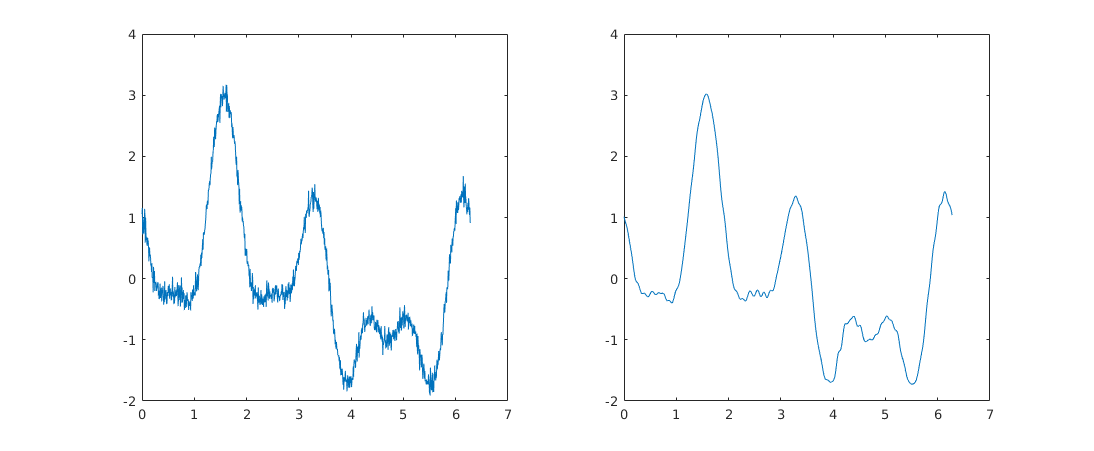

Segnale rumoroso e risultato del filtro nella dispensa originale.

## 3. Trasformate 2D e compressione di immagini

Realizziamo una versione molto semplificata di un compressore basato sulla DCT. Un’immagine in scala di grigi è una matrice di intensità: possiamo immaginarla come campionamento di una funzione su $[0,1]^2$. Molte immagini hanno buona parte dell’informazione nelle basse frequenze.

Lavoriamo con `test1-bw.jpg`, incluso nel notebook. In Julia un’immagine caricata è una matrice di colori; `Float64.(Gray.(img))` produce intensità in $[0,1]$. Moltiplicando per $255$ lavoriamo con la scala della dispensa, ma manteniamo numeri floating point per le trasformate.

In [ ]:
using FileIO
using ImageIO
using Colors
using Base64

La cella seguente ricostruisce l’immagine originale incorporata nel notebook in una directory temporanea e la carica. Questa copia permette di eseguire la lezione anche senza il resto del repository.

In [ ]:
immagine_base64 = """
...
s4KOGAF4oAB//9k=
"""
img_originale = mktempdir() do cartella
    percorso = joinpath(cartella, "test1-bw.jpg")
    write(percorso, base64decode(immagine_base64))
    load(percorso)
end
M = 255 .* Float64.(Gray.(img_originale))
size(M)

In [ ]:
heatmap(M; color=:grays, clims=(0, 255), yflip=true, aspect_ratio=:equal, colorbar=false, axis=false, ticks=false)

Usiamo la trasformata discreta dei coseni di tipo II (DCT-II). In `FFTW`, `dct` usa la normalizzazione ortonormale; `idct` ne è l’inversa. Le basse frequenze sono nelle prime entrate. Su una matrice, `dct(B, (1, 2))` trasforma entrambe le dimensioni: sostituisce `dct2` di MATLAB.

Per approfondire il legame con la FFT potete leggere i file `dct.m` e `idct.m` originali della lezione. Usiamo sempre una trasformata e un’inversa con normalizzazioni compatibili.

In [ ]:
B = M[1:32, 1:32]
D = dct(B, (1, 2))
norm(idct(D, (1, 2)) - B) / max(norm(B), 1.0)

### Esercizio 8

Scrivete `myjpeg(M, t)` con $1\leq t\leq32$ intero, per un’immagine di dimensione $m\times n$ con entrambe le dimensioni multiple di 32:

1. Suddividete l’immagine in blocchi $32\times32$.
2. Calcolate la DCT bidimensionale di ogni blocco.
3. Conservate solo il blocco in alto a sinistra $t\times t$ di coefficienti, nella corrispondente posizione della matrice di output.

L’output `C` deve avere dimensione $(m/32)t\times(n/32)t$. Usate `div(m,32)*t` per ottenere dimensioni intere; i coefficienti possono essere negativi e devono restare floating point.

Scrivete poi `myjpegdecode(C, t)` che:

1. Divida `C` in blocchi $t\times t$.
2. Inserisca ogni blocco nell’angolo in alto a sinistra di una matrice nulla $32\times32$.
3. Applichi `idct` lungo entrambe le dimensioni e ricomponga l’immagine.

Restituite intensità floating point in scala $0$–$255$. Per visualizzarle come immagine usate `Gray.(clamp.(M_dec ./ 255, 0, 1))`. Se volete interi a 8 bit, usate `round.(UInt8, clamp.(M_dec, 0, 255))`: a differenza di MATLAB, `UInt8` non arrotonda e satura automaticamente valori fuori intervallo.

Testate $t=32$: prima del ritaglio e dell’arrotondamento, l’errore deve essere vicino alla precisione di macchina. Provate poi $t=16$, $8$ e valori minori, cercando gli artefatti ai bordi dei blocchi. Controllate gli input e gestite dimensioni non multiple di 32, per esempio ritagliandole esplicitamente prima della chiamata.

In [ ]:
# Scrivete qui la soluzione e gli esperimenti per l’esercizio 8

In [ ]:
# Preparazione valida anche per altre immagini:
m, n = size(M)
M_test = M[1:32*div(m, 32), 1:32*div(n, 32)]
# C = myjpeg(M_test, 8)
# M_dec = myjpegdecode(C, 8)
# heatmap(M_dec; color=:grays, clims=(0, 255), yflip=true,
#         aspect_ratio=:equal, colorbar=false, axis=false, ticks=false)
# C32 = myjpeg(M_test, 32)
# norm(myjpegdecode(C32, 32) - M_test) / norm(M_test)

Assumendo che un’entrata di `M` e una di `C` occupino lo stesso spazio, qual è il rapporto di compressione in funzione di `t`? E se l’immagine iniziale è memorizzata come `UInt8` e i coefficienti come `Float64`? Distinguete il numero di coefficienti dalla dimensione di un file JPEG su disco.

La procedura riproduce solo l’idea della rimozione delle alte frequenze. Non scrive un file JPEG: mancano quantizzazione e codifica dei coefficienti. Nel JPEG usuale a colori si usa una rappresentazione di luminanza e crominanza (tipicamente YCbCr), spesso con sottocampionamento della crominanza e DCT su blocchi 8×8. La dispensa cita invece HSV e blocchi 16×16; qui i blocchi 32×32 sono una scelta didattica.

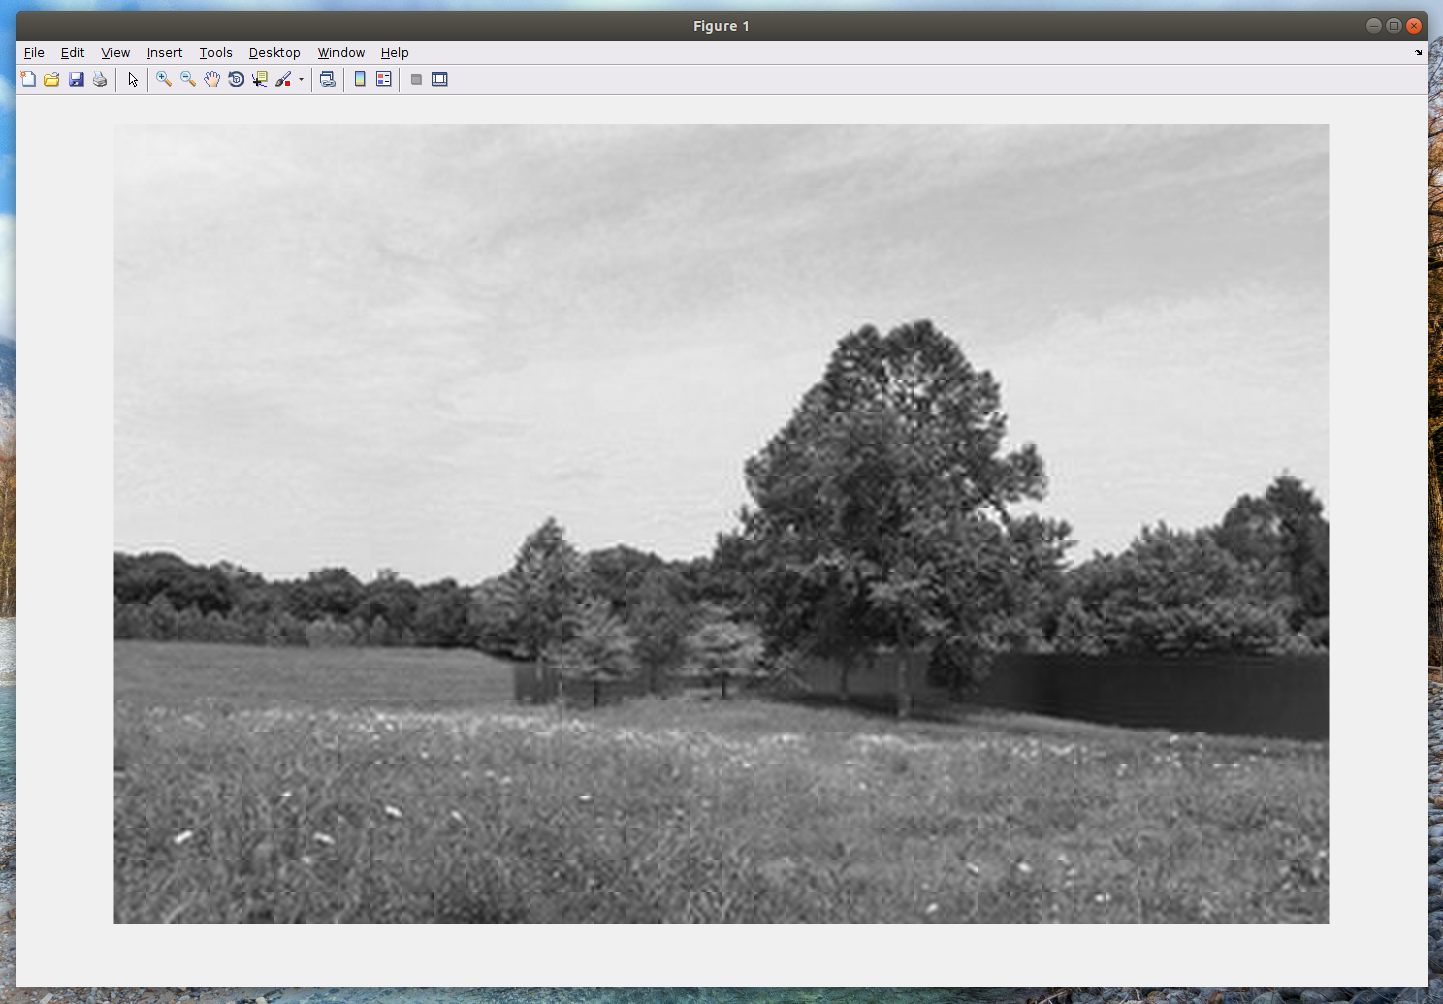

Ricostruzione con t = 8 nella dispensa originale: osservate gli artefatti dei blocchi.

Riferimenti per gli adattamenti: [FFTW.jl: DCT-II ortonormale e inversa](https://juliamath.github.io/FFTW.jl/stable/fft/) e [AbstractFFTs.jl: convenzioni della FFT](https://juliamath.github.io/AbstractFFTs.jl/stable/api/).